<div style="background:linear-gradient(135deg,#083344 0%,#0e7490 55%,#06b6d4 100%);border-radius:18px;padding:34px 30px;color:#fff;font-family:Inter,Segoe UI,sans-serif">
  <div style="font-size:12px;letter-spacing:3px;color:#a5f3fc;font-weight:700;text-transform:uppercase">Chapter 86 · Case Study · Inference</div>
  <div style="font-size:33px;font-weight:900;line-height:1.1;margin:10px 0 6px">Case Study: A Web A/B Test 🌐</div>
  <div style="font-size:15px;color:#ecfeff;max-width:760px;line-height:1.6">A redesigned landing page, a randomized experiment, and one clean question: did it convert better? We explore the data first, confirm the test, then let statsmodels run the two-proportion z-test and the lift interval, and write the recommendation.</div>
  <div style="margin-top:16px;font-size:13px;color:#a5f3fc">Statistics, Data Science and AI: A Visual Handbook · John Fisher · 2026</div>
</div>

## ⚙️ Setup

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
# statsmodels = the R/SAS-style stats library (pre-installed on Colab): it does the standard errors,
# test statistics, intervals, and post-hoc comparisons for us, so we write far less by-hand code.
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_confint
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.weightstats import DescrStatsW, CompareMeans
from scipy.stats.contingency import association   # Cramer's V in one call
CY="#0891b2"; DEEP="#0e7490"; LIGHT="#67e8f9"; INK="#1a2138"; GRID="#e6e9f2"; GREEN="#059669"; RED="#ef4444"; AMBER="#d97706"
plt.rcParams.update({"figure.facecolor":"white","axes.facecolor":"white","figure.dpi":110,"font.size":11,
   "axes.edgecolor":GRID,"axes.grid":True,"grid.color":GRID,"axes.axisbelow":True,"axes.spines.top":False,
   "axes.spines.right":False,"axes.titlesize":12,"axes.titleweight":"bold","legend.frameon":False})
pd.set_option("display.width",120)
BASE="https://raw.githubusercontent.com/johnfisher-ai/Statistics-Data-Science-AI-Visual-Book/main/data/"
rng = np.random.default_rng(84)

<div style="background:#ecfeff;border-left:5px solid #0891b2;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#0e7490;letter-spacing:1px">STEP 1 · EXPLORE THE DATA</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">Get a feel before running any test</div>
<div style="color:#4a5578;margin-top:6px">A statistician never tests first. We load the export, check its size and for missing values, summarize it, and confirm the randomization actually balanced the two groups (here, device mix), because a broken randomization would invalidate everything that follows.</div>
</div>

In [2]:
try:    e = pd.read_excel("../../data/case-study-a-web-a-b-test--web_abtest.xlsx", sheet_name="Sessions")
except FileNotFoundError: e = pd.read_excel(BASE+"case-study-a-web-a-b-test--web_abtest.xlsx", sheet_name="Sessions")
print("shape:", e.shape, "| missing values:", e.isna().sum().sum())
display(e.describe(include="all").T[["count","unique","top","mean"]])

shape: (3600, 7) | missing values: 0


,count,unique,top,mean
session_id,3600,3600,S403599,NaN
variant,3600,2,A,NaN
device,3600,3,mobile,NaN
landing_page,3600,2,control,NaN
seconds_on_page,3600.0,NaN,NaN,54.232194
converted,3600.0,NaN,NaN,0.116111
visit_date,3600,10,2026-05-04,NaN


In [3]:
# conversion and time-on-page by variant
print(e.groupby("variant").agg(sessions=("converted","size"), conv_rate=("converted","mean"),
                               avg_seconds=("seconds_on_page","mean")).round(3))
# randomization check: device mix should be similar across A and B
print("\ndevice mix by variant (should be balanced):")
print(pd.crosstab(e.variant, e.device, normalize="index").round(3))

         sessions  conv_rate  avg_seconds
variant                                  
A            1830      0.099       54.410
B            1770      0.134       54.048

device mix by variant (should be balanced):
device   desktop  mobile  tablet
variant                         
A          0.309   0.610   0.081
B          0.328   0.596   0.076


The data is clean (no missing values), the two arms are similar in size, and the device mix is close across A and B (desktop 30.9% vs 32.8%), as a random split should leave it. B&#39;s raw conversion looks higher; now we test it.

<div style="background:#ecfeff;border-left:5px solid #0891b2;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#0e7490;letter-spacing:1px">STEP 2 · CHOOSE THE TEST & STATE THE HYPOTHESES</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">A yes/no outcome in two independent groups</div>
<div style="color:#4a5578;margin-top:6px">Outcome = converted (yes/no) -> a PROPORTION. Two independent groups -> the two-proportion z-test. We expect B to be better, so the alternative is one-sided.</div>
</div>

In [4]:
print("Decision: proportion outcome + 2 independent groups -> TWO-PROPORTION z-TEST")
print("H0: pB = pA   (the redesign does not change conversion)")
print("H1: pB > pA   (the redesign converts better) -- one-sided")
A=e[e.variant=="A"]; B=e[e.variant=="B"]
cA,nA=A.converted.sum(),len(A); cB,nB=B.converted.sum(),len(B)
print(f"\nsuccess-failure check: A {cA}/{nA-cA}, B {cB}/{nB-cB} (all >> 10 -> z is valid)")

Decision: proportion outcome + 2 independent groups -> TWO-PROPORTION z-TEST
H0: pB = pA   (the redesign does not change conversion)
H1: pB > pA   (the redesign converts better) -- one-sided

success-failure check: A 181/1649, B 237/1533 (all >> 10 -> z is valid)


<div style="background:#ecfeff;border-left:5px solid #0891b2;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#0e7490;letter-spacing:1px">STEP 3 · RUN THE ANALYSIS</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">Let statsmodels do the standard errors</div>
<div style="color:#4a5578;margin-top:6px">Instead of coding the pooled standard error and z by hand, we call statsmodels: proportions_ztest for the test and confint_proportions_2indep for the lift interval. Two function calls replace a dozen lines of algebra.</div>
</div>

In [5]:
# the test: counts and sample sizes for [B, A], one-sided "larger"
z, p_one = proportions_ztest([cB, cA], [nB, nA], alternative="larger")
# the 95% confidence interval for the lift (pB - pA)
lo, hi = confint_proportions_2indep(cB, nB, cA, nA, method="wald")
pA, pB = cA/nA, cB/nB
print(f"A = {pA:.2%}, B = {pB:.2%}, absolute lift = {(pB-pA)*100:+.2f} pts, relative lift = {(pB/pA-1)*100:+.1f}%")
print(f"two-proportion z-test: z = {z:.2f}, one-sided p = {p_one:.4f}")
print(f"95% CI for the lift: [{lo*100:+.2f}, {hi*100:+.2f}] pts")
print("REJECT H0: the redesign converts significantly better" if p_one<0.05 else "fail to reject H0")

A = 9.89%, B = 13.39%, absolute lift = +3.50 pts, relative lift = +35.4%
two-proportion z-test: z = 3.28, one-sided p = 0.0005
95% CI for the lift: [+1.40, +5.59] pts
REJECT H0: the redesign converts significantly better


design power at ~1830 per arm, 10% baseline, +2 pts: 0.61
design power at ~1830 per arm, 10% baseline, +3 pts: 0.88
lift detectable with 80% power: about +2.6 pts


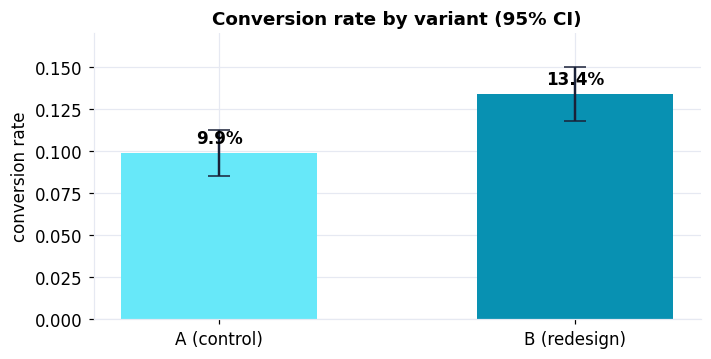

In [6]:
# was the test adequately powered? Judge it at the design stage, from a 10% baseline and lifts set in advance
# (power at the observed lift only restates the p-value)
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.power import NormalIndPower
pw, base = NormalIndPower(), 0.10
for lift in [0.02, 0.03]:
    power = pw.power(effect_size=proportion_effectsize(base+lift, base), nobs1=nA, alpha=0.05, ratio=nB/nA, alternative="larger")
    print(f"design power at ~{nA} per arm, {base:.0%} baseline, +{lift*100:.0f} pts: {power:.2f}")
h80 = pw.solve_power(nobs1=nA, alpha=0.05, power=0.80, ratio=nB/nA, alternative="larger")
mde = np.sin(np.arcsin(np.sqrt(base)) + h80/2)**2 - base   # turn Cohen's h back into a lift
print(f"lift detectable with 80% power: about +{mde*100:.1f} pts")
fig,ax=plt.subplots(figsize=(6.6,3.4))
ax.bar(["A (control)","B (redesign)"],[pA,pB],color=[LIGHT,CY],width=0.55)
ax.errorbar([0,1],[pA,pB],yerr=[1.96*np.sqrt(pA*(1-pA)/nA),1.96*np.sqrt(pB*(1-pB)/nB)],fmt="none",ecolor=INK,capsize=7,lw=1.6)
for i,v in enumerate([pA,pB]): ax.text(i,v+0.006,f"{v:.1%}",ha="center",fontweight="bold")
ax.set_ylim(0,0.17); ax.set_ylabel("conversion rate"); ax.set_title("Conversion rate by variant (95% CI)")
plt.tight_layout(); plt.show()

The lift is about <strong>+3.5 points</strong> (a relative gain near 35%), the one-sided p is around <strong>0.0005</strong>, and the 95% interval for the lift (roughly +1.4 to +5.6 points) sits entirely above zero. At the design stage the test had 88% power for a 3-point lift and 61% for 2 points, and the observed 3.5-point lift is above the 2.6 points it detects with 80% power.

<div style="background:#ffffff;border:1px solid #cffafe;border-left:5px solid #0e7490;border-radius:12px;padding:18px 22px;font-family:Inter,sans-serif">
<div style="font-size:12px;font-weight:800;color:#0e7490;letter-spacing:1px">📋 STATISTICIAN’S REPORT</div>
<div style="font-size:18px;font-weight:800;color:#1a2138;margin:4px 0 8px">Recommendation: ship the redesign</div>
<div style="color:#3f4a63;line-height:1.75"><strong>What we found.</strong> The redesigned page (B) converted at <strong>13.4%</strong> versus <strong>9.9%</strong> for the current page (A), a lift of about <strong>3.5 percentage points</strong> (roughly a 35% relative increase). <br><br><strong>How confident are we?</strong> Very. If the redesign truly made no difference, a gap this large would appear by chance only about <strong>1 in 2,000</strong> times (p &#8776; 0.0005). Our best estimate of the gain is a range of <strong>+1.4 to +5.6 points</strong> (95% confidence), and even the cautious end, +1.4 points, is a gain of about 14% over the current page. <br><br><strong>What to do.</strong> Roll the redesign out to all traffic. Because visitors were randomly assigned (and the device mix is close in both arms), a gain this far beyond chance can be credited to the page itself. <br><br><strong>One caveat.</strong> This measures conversion during the test window only. After launch, keep an eye on revenue per order and longer-term metrics to confirm the gain holds.</div>
</div>

---
<div style="text-align:center;color:#8b94b3;font-size:12px;margin-top:10px">Statistics, Data Science and AI: A Visual Handbook · © 2026 John Fisher</div>